In [88]:

!pip install -q ucimlrepo openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [89]:

from ucimlrepo import fetch_ucirepo

retail = fetch_ucirepo(id=352)

df = retail.data.features.copy()

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (541909, 6)


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [90]:


print(df.info())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Statistical summary
display(df.describe())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB
None

Missing values:
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


Duplicate rows: 6007


In [91]:


df_original = df.copy()

print("Original rows:", len(df_original))
print("Columns:", df.columns.tolist())


Original rows: 541909
Columns: ['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [92]:


missing = df.isnull().sum()

# Percentage of missing values
missing_percent = (missing / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percent.round(2)
})

display(missing_report)


,Missing Values,Percentage
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [93]:

df = df.drop_duplicates()

print(df.shape)


(535902, 6)


In [94]:

df = df.dropna(subset=['CustomerID', 'Description'])

print(df.isnull().sum())


Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [95]:


df = df[~df['InvoiceDate'].astype(str).str.startswith('C')]

print(df.shape)



(401528, 6)


In [96]:

df = df[df['Quantity'] > 0]

df = df[df['UnitPrice'] > 0]

print(df.shape)


(392617, 6)


In [97]:

df['TotalSales'] = df['Quantity'] * df['UnitPrice']

df.head()


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom,15.30
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom,22.00
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34


In [98]:

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['Month'] = df['InvoiceDate'].dt.month

df['Year'] = df['InvoiceDate'].dt.year

df.head()


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Month,Year
0,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010
1,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
2,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
4,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010


In [99]:

df.to_csv('cleaned_sales.csv', index=False)

print("Dataset cleaned successfully!")


Dataset cleaned successfully!


In [100]:

total_sales = df['TotalSales'].sum()

print("Total Revenue:", round(total_sales, 2))


Total Revenue: 8885586.15


In [101]:

top_products = df.groupby('Description')['Quantity'].sum()

top_products = top_products.sort_values(ascending=False)

print(top_products.head(10))


Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30915
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


In [102]:

country_sales = df.groupby('Country')['TotalSales'].sum()

country_sales = country_sales.sort_values(ascending=False)

print(country_sales.head(10))


Country
United Kingdom    7283438.304
Netherlands        285446.340
EIRE               265262.460
Germany            228660.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: TotalSales, dtype: float64


In [103]:

monthly_sales = df.groupby(['Year', 'Month'])['TotalSales'].sum()

print(monthly_sales)


Year  Month
2010  12        570356.630
2011  1         568028.710
      2         446082.420
      3         594039.460
      4         468369.331
      5         677248.950
      6         660044.800
      7         598043.151
      8         644041.040
      9         950475.552
      10       1035537.210
      11       1156148.360
      12        517170.540
Name: TotalSales, dtype: float64


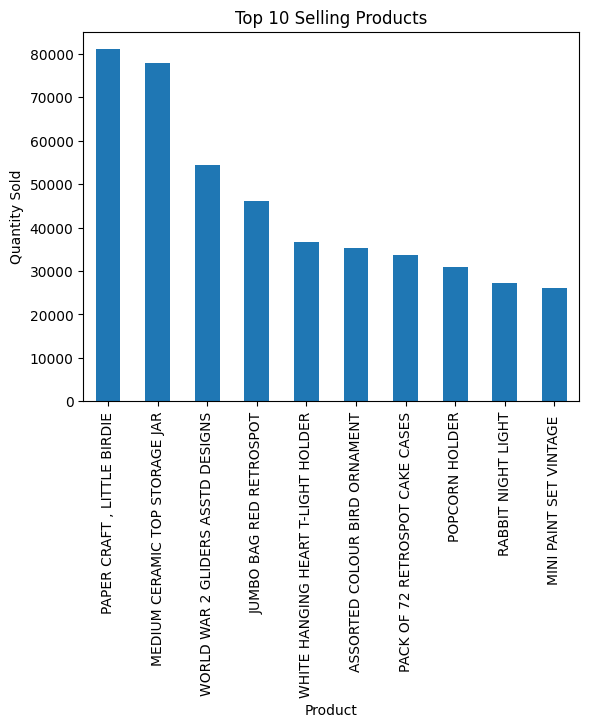

In [104]:

top_products.head(10).plot(kind='bar')

plt.title('Top 10 Selling Products')
plt.xlabel('Product')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=90)
plt.show()


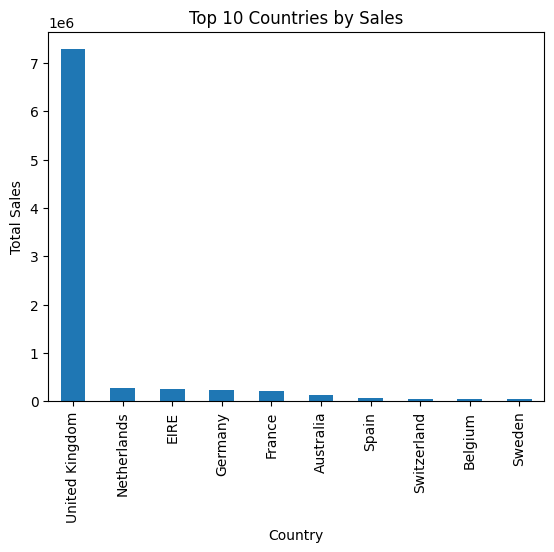

In [105]:

country_sales.head(10).plot(kind='bar')

plt.title('Top 10 Countries by Sales')
plt.xlabel('Country')
plt.ylabel('Total Sales')
plt.show()


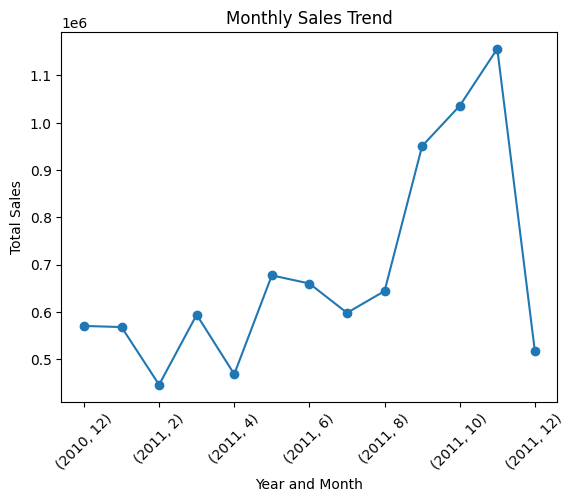

In [106]:

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Year and Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()


In [107]:

df.to_csv('cleaned_sales.csv', index=False)

print("File saved successfully")


File saved successfully


In [108]:

import sqlite3

conn = sqlite3.connect('sales.db')

print("Database created")


Database created


In [109]:

df.to_sql('sales', conn, if_exists='replace', index=False)

print("Data added successfully")


Data added successfully


In [110]:

query = "SELECT * FROM sales LIMIT 5"

result = pd.read_sql(query, conn)

print(result)


                           Description  Quantity          InvoiceDate  \
0   WHITE HANGING HEART T-LIGHT HOLDER         6  2010-12-01 08:26:00   
1                  WHITE METAL LANTERN         6  2010-12-01 08:26:00   
2       CREAM CUPID HEARTS COAT HANGER         8  2010-12-01 08:26:00   
3  KNITTED UNION FLAG HOT WATER BOTTLE         6  2010-12-01 08:26:00   
4       RED WOOLLY HOTTIE WHITE HEART.         6  2010-12-01 08:26:00   

   UnitPrice  CustomerID         Country  TotalSales  Month  Year  
0       2.55     17850.0  United Kingdom       15.30     12  2010  
1       3.39     17850.0  United Kingdom       20.34     12  2010  
2       2.75     17850.0  United Kingdom       22.00     12  2010  
3       3.39     17850.0  United Kingdom       20.34     12  2010  
4       3.39     17850.0  United Kingdom       20.34     12  2010  


In [111]:

query = """
SELECT SUM(TotalSales) AS Revenue
FROM sales
"""

result = pd.read_sql(query, conn)

print(result)


       Revenue
0  8885586.154


In [112]:

query = """
SELECT Description, SUM(Quantity) AS TotalQuantity
FROM sales
GROUP BY Description
ORDER BY TotalQuantity DESC
LIMIT 10
"""

result = pd.read_sql(query, conn)

print(result)


                          Description  TotalQuantity
0         PAPER CRAFT , LITTLE BIRDIE          80995
1      MEDIUM CERAMIC TOP STORAGE JAR          77916
2   WORLD WAR 2 GLIDERS ASSTD DESIGNS          54319
3             JUMBO BAG RED RETROSPOT          46078
4  WHITE HANGING HEART T-LIGHT HOLDER          36706
5       ASSORTED COLOUR BIRD ORNAMENT          35263
6     PACK OF 72 RETROSPOT CAKE CASES          33670
7                      POPCORN HOLDER          30915
8                  RABBIT NIGHT LIGHT          27153
9             MINI PAINT SET VINTAGE           26076


In [113]:

query = """
SELECT Country, SUM(TotalSales) AS Revenue
FROM sales
GROUP BY Country
ORDER BY Revenue DESC
"""

result = pd.read_sql(query, conn)

print(result.head(10))


          Country      Revenue
0  United Kingdom  7283438.304
1     Netherlands   285446.340
2            EIRE   265262.460
3         Germany   228660.400
4          France   208934.310
5       Australia   138453.810
6           Spain    61558.560
7     Switzerland    56443.950
8         Belgium    41196.340
9          Sweden    38367.830


In [114]:

query = """
SELECT CustomerID, SUM(TotalSales) AS TotalSpent
FROM sales
GROUP BY CustomerID
ORDER BY TotalSpent DESC
LIMIT 10
"""

result = pd.read_sql(query, conn)

print(result)


   CustomerID  TotalSpent
0     14646.0   280206.02
1     18102.0   258741.30
2     17450.0   194390.79
3     16446.0   168472.50
4     14911.0   143711.17
5     12415.0   124914.53
6     14156.0   117210.08
7     17511.0    91062.38
8     16029.0    80673.24
9     12346.0    77183.60


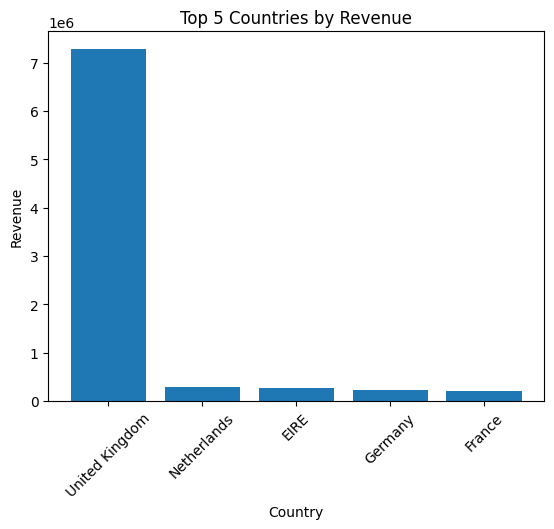

In [115]:

query = """
SELECT Country, SUM(TotalSales) AS Revenue
FROM sales
GROUP BY Country
ORDER BY Revenue DESC
LIMIT 5
"""

result = pd.read_sql(query, conn)

plt.bar(result['Country'], result['Revenue'])

plt.title('Top 5 Countries by Revenue')
plt.xlabel('Country')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.show()


In [116]:

from google.colab import files

df.to_csv('cleaned_sales.csv', index=False)

files.download('cleaned_sales.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [137]:
with open("sales_queries.sql", "w") as file:
    file.write(query)
from google.colab import files

files.download("sales_queries.sql")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Business Insights & Analysis**

In [117]:

revenue = df['TotalSales'].sum()

print("Total Revenue:", round(revenue, 2))


Total Revenue: 8885586.15


In [118]:

country_sales = df.groupby('Country')['TotalSales'].sum()

country_sales = country_sales.sort_values(ascending=False)

print(country_sales.head(5))


Country
United Kingdom    7283438.304
Netherlands        285446.340
EIRE               265262.460
Germany            228660.400
France             208934.310
Name: TotalSales, dtype: float64


In [119]:

country_percentage = country_sales / revenue * 100

print(country_percentage.head(5).round(2))


Country
United Kingdom    81.97
Netherlands        3.21
EIRE               2.99
Germany            2.57
France             2.35
Name: TotalSales, dtype: float64


In [120]:

product_sales = df.groupby('Description')['TotalSales'].sum()

product_sales = product_sales.sort_values(ascending=False)

print(product_sales.head(10))


Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77785.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: TotalSales, dtype: float64


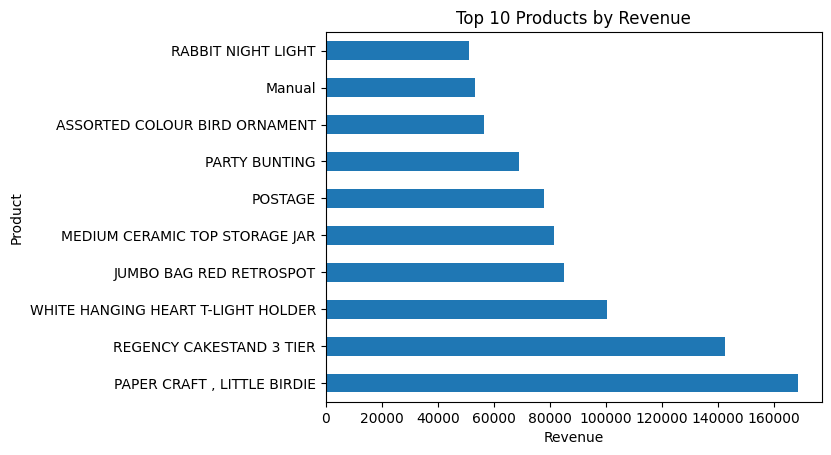

In [121]:

product_sales.head(10).plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')

plt.show()


In [122]:

customer_sales = df.groupby('CustomerID')['TotalSales'].sum()

customer_sales = customer_sales.sort_values(ascending=False)

print(customer_sales.head(10))


CustomerID
14646.0    280206.02
18102.0    258741.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80673.24
12346.0     77183.60
Name: TotalSales, dtype: float64


In [123]:

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['MonthYear'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('MonthYear')['TotalSales'].sum()

print(monthly_sales)


MonthYear
2010-12     570356.630
2011-01     568028.710
2011-02     446082.420
2011-03     594039.460
2011-04     468369.331
2011-05     677248.950
2011-06     660044.800
2011-07     598043.151
2011-08     644041.040
2011-09     950475.552
2011-10    1035537.210
2011-11    1156148.360
2011-12     517170.540
Freq: M, Name: TotalSales, dtype: float64


In [131]:

growth = monthly_sales.pct_change() * 100

print(growth.round(2))


MonthYear
2010-12      NaN
2011-01    -0.41
2011-02   -21.47
2011-03    33.17
2011-04   -21.16
2011-05    44.60
2011-06    -2.54
2011-07    -9.39
2011-08     7.69
2011-09    47.58
2011-10     8.95
2011-11    11.65
2011-12   -55.27
Freq: M, Name: TotalSales, dtype: float64


In [132]:

orders = df['InvoiceDate'].nunique()

average_order = revenue / orders

print("Total Orders:", orders)
print("Average Order Value:", round(average_order, 2))


Total Orders: 17282
Average Order Value: 514.15


In [129]:

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['MonthYear'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('MonthYear')['TotalSales'].sum()

print(monthly_sales)


MonthYear
2010-12     570356.630
2011-01     568028.710
2011-02     446082.420
2011-03     594039.460
2011-04     468369.331
2011-05     677248.950
2011-06     660044.800
2011-07     598043.151
2011-08     644041.040
2011-09     950475.552
2011-10    1035537.210
2011-11    1156148.360
2011-12     517170.540
Freq: M, Name: TotalSales, dtype: float64


In [133]:

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['MonthYear'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('MonthYear')['TotalSales'].sum()

print(monthly_sales)


MonthYear
2010-12     570356.630
2011-01     568028.710
2011-02     446082.420
2011-03     594039.460
2011-04     468369.331
2011-05     677248.950
2011-06     660044.800
2011-07     598043.151
2011-08     644041.040
2011-09     950475.552
2011-10    1035537.210
2011-11    1156148.360
2011-12     517170.540
Freq: M, Name: TotalSales, dtype: float64


In [126]:

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['MonthYear'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('MonthYear')['TotalSales'].sum()

print(monthly_sales)


MonthYear
2010-12     570356.630
2011-01     568028.710
2011-02     446082.420
2011-03     594039.460
2011-04     468369.331
2011-05     677248.950
2011-06     660044.800
2011-07     598043.151
2011-08     644041.040
2011-09     950475.552
2011-10    1035537.210
2011-11    1156148.360
2011-12     517170.540
Freq: M, Name: TotalSales, dtype: float64


In [134]:

print("ECOMMERCE SALES REPORT")
print("----------------------")

print("Total Revenue:", round(revenue, 2))
print("Total Orders:", orders)
print("Average Order Value:", round(average_order, 2))

print("\nTop Country:")
print(country_sales.head(1))

print("\nTop Product:")
print(product_sales.head(1))

print("\nTop Customer:")
print(customer_sales.head(1))


ECOMMERCE SALES REPORT
----------------------
Total Revenue: 8885586.15
Total Orders: 17282
Average Order Value: 514.15

Top Country:
Country
United Kingdom    7283438.304
Name: TotalSales, dtype: float64

Top Product:
Description
PAPER CRAFT , LITTLE BIRDIE    168469.6
Name: TotalSales, dtype: float64

Top Customer:
CustomerID
14646.0    280206.02
Name: TotalSales, dtype: float64
